# Nhiệm vụ 1.2: Phân tích Biến Giá (price_vnd, original_price_vnd, discount_rate) & Thử nghiệm Biến đổi Log

**Thành viên thực hiện**: TV3 (Exploratory Data Analysis)

**Tập dữ liệu đầu vào**: `data/processed/products_processed.jsonl`

**Mục tiêu**:
1. Tính toán các chỉ số thống kê mô tả toàn diện cho biến giá bán quan sát (`price_vnd`): Mean, Median, Std, IQR, Skewness, Kurtosis.
2. So sánh trực quan phân phối giá giữa **Laptop** và **Smartphone** qua biểu đồ Histogram, KDE và Boxplot.
3. Chứng minh toán học lợi ích của phép biến đổi Log đối với mô hình hồi quy (giảm Skewness và Kurtosis).
4. Khảo sát chính sách chiết khấu (`discount_rate`) theo 5 sàn bán lẻ.

In [1]:
import os
import sys
from pathlib import Path

# Tự động định vị REPO_ROOT (chứa data/processed) và đưa working directory về root
curr = Path.cwd().resolve()
while curr != curr.parent:
    if (curr / "data" / "processed" / "products_processed.jsonl").exists():
        os.chdir(curr)
        break
    curr = curr.parent

if "src/eda/scripts" not in sys.path:
    sys.path.insert(0, "src/eda/scripts")

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from eda_stats import (
    load_processed_products,
    compute_price_descriptive_stats,
    compute_price_log_comparison,
    compute_discount_stats_by_source
)
from eda_viz import (
    set_plotting_theme,
    plot_price_distribution_and_log_transform,
    plot_discount_rate_by_source
)

set_plotting_theme()
print("Môi trường phân tích sẵn sàng!")

Môi trường phân tích sẵn sàng!


## 1. Tải dữ liệu và Thống kê mô tả Giá bán (price_vnd)

In [2]:
df = load_processed_products("data/processed/products_processed.jsonl")
price_stats_df = compute_price_descriptive_stats(df)
display(price_stats_df)

,Số mẫu hợp lệ,Số mẫu thiếu/0đ,Mean (Tr.đ),Std (Tr.đ),Min (Tr.đ),Q1 25% (Tr.đ),Median 50% (Tr.đ),Q3 75% (Tr.đ),IQR (Tr.đ),Max (Tr.đ),Skewness (Độ lệch),Kurtosis (Độ nhọn)
Phân nhóm,,,,,,,,,,,,
Toàn thị trường,8548,1768,23.37,21.77,0.00,7.89,19.49,29.99,22.1,485.00,3.47,34.48
Laptop,4222,652,32.99,22.54,1.69,19.29,26.84,38.99,19.7,269.99,2.89,13.54
Smartphone,4326,1116,13.99,16.21,0.00,3.99,7.99,20.09,16.1,485.00,7.38,170.71


## 2. Thử nghiệm Biến đổi Log và Đánh giá Tính chuẩn (Normality)

In [3]:
log_comp_df = compute_price_log_comparison(df)
display(log_comp_df)

,Raw Skewness,Log10 Skewness,Raw Kurtosis,Log10 Kurtosis,Đánh giá dạng phân phối
Phân nhóm,,,,,
Toàn thị trường,3.47,-1.00,34.48,1.63,Hơi lệch trái
Laptop,2.89,0.29,13.54,1.07,Gần chuẩn (Bell-shaped)
Smartphone,7.38,-0.58,170.71,0.89,Gần chuẩn (Bell-shaped)


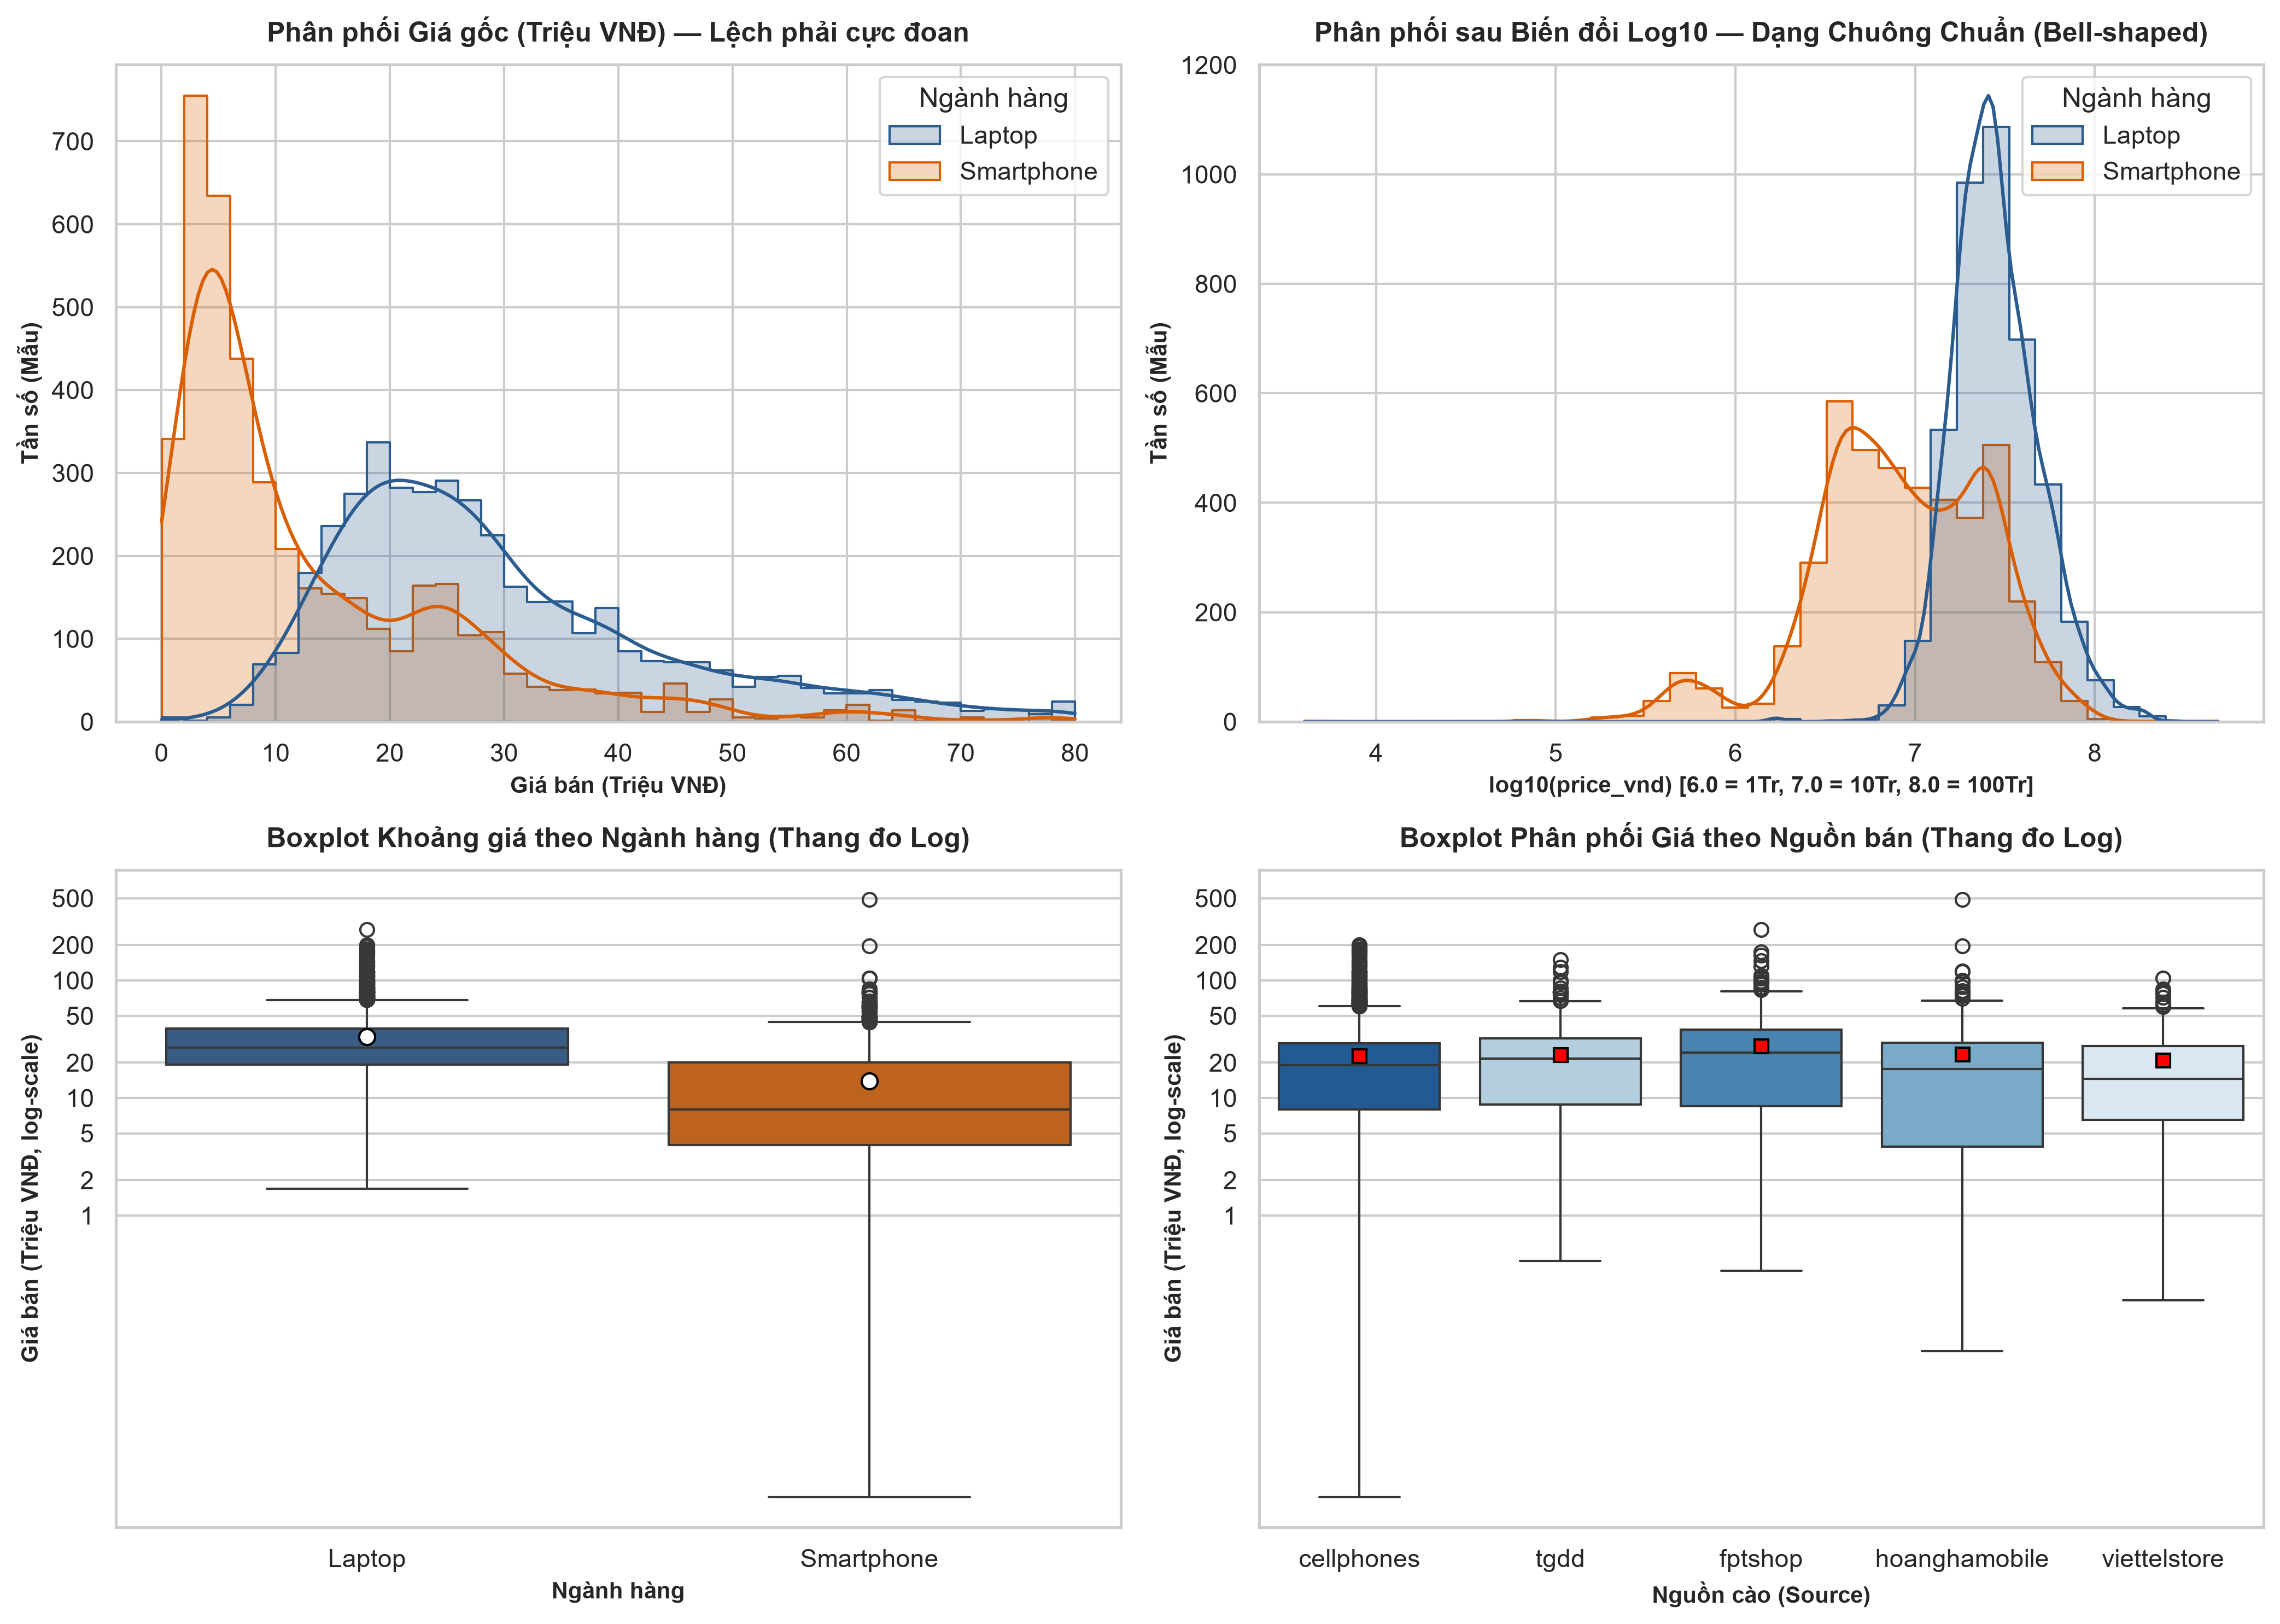

In [4]:
fig1_path = "src/eda/outputs/figures/fig_1_2_price_distribution_and_log_transform.png"
plot_price_distribution_and_log_transform(df, fig1_path)
from IPython.display import Image, display
display(Image(fig1_path))


## 3. Khảo sát Tỷ lệ Chiết khấu (discount_rate) theo Nguồn sàn

,Số mẫu có giảm giá,Tỷ lệ có giảm giá (%),Mean (%),Std (%),Min (%),Q1 25% (%),Median (%),Q3 75% (%),Max (%),Skewness
cellphones,6083.0,77.52,11.70,11.33,0.00,0.89,8.57,19.23,57.97,0.94
fptshop,819.0,99.88,7.95,7.61,0.00,2.22,6.16,10.95,38.91,1.18
hoanghamobile,258.0,90.53,20.81,23.07,0.00,7.50,14.61,23.15,99.44,2.40
tgdd,443.0,37.01,9.05,6.55,0.00,4.39,7.22,12.29,29.18,1.08
viettelstore,134.0,80.24,14.53,12.74,0.64,7.29,12.14,17.26,98.00,4.29
Toàn thị trường,7737.0,75.00,11.50,11.61,0.00,2.22,8.34,18.19,99.44,1.78


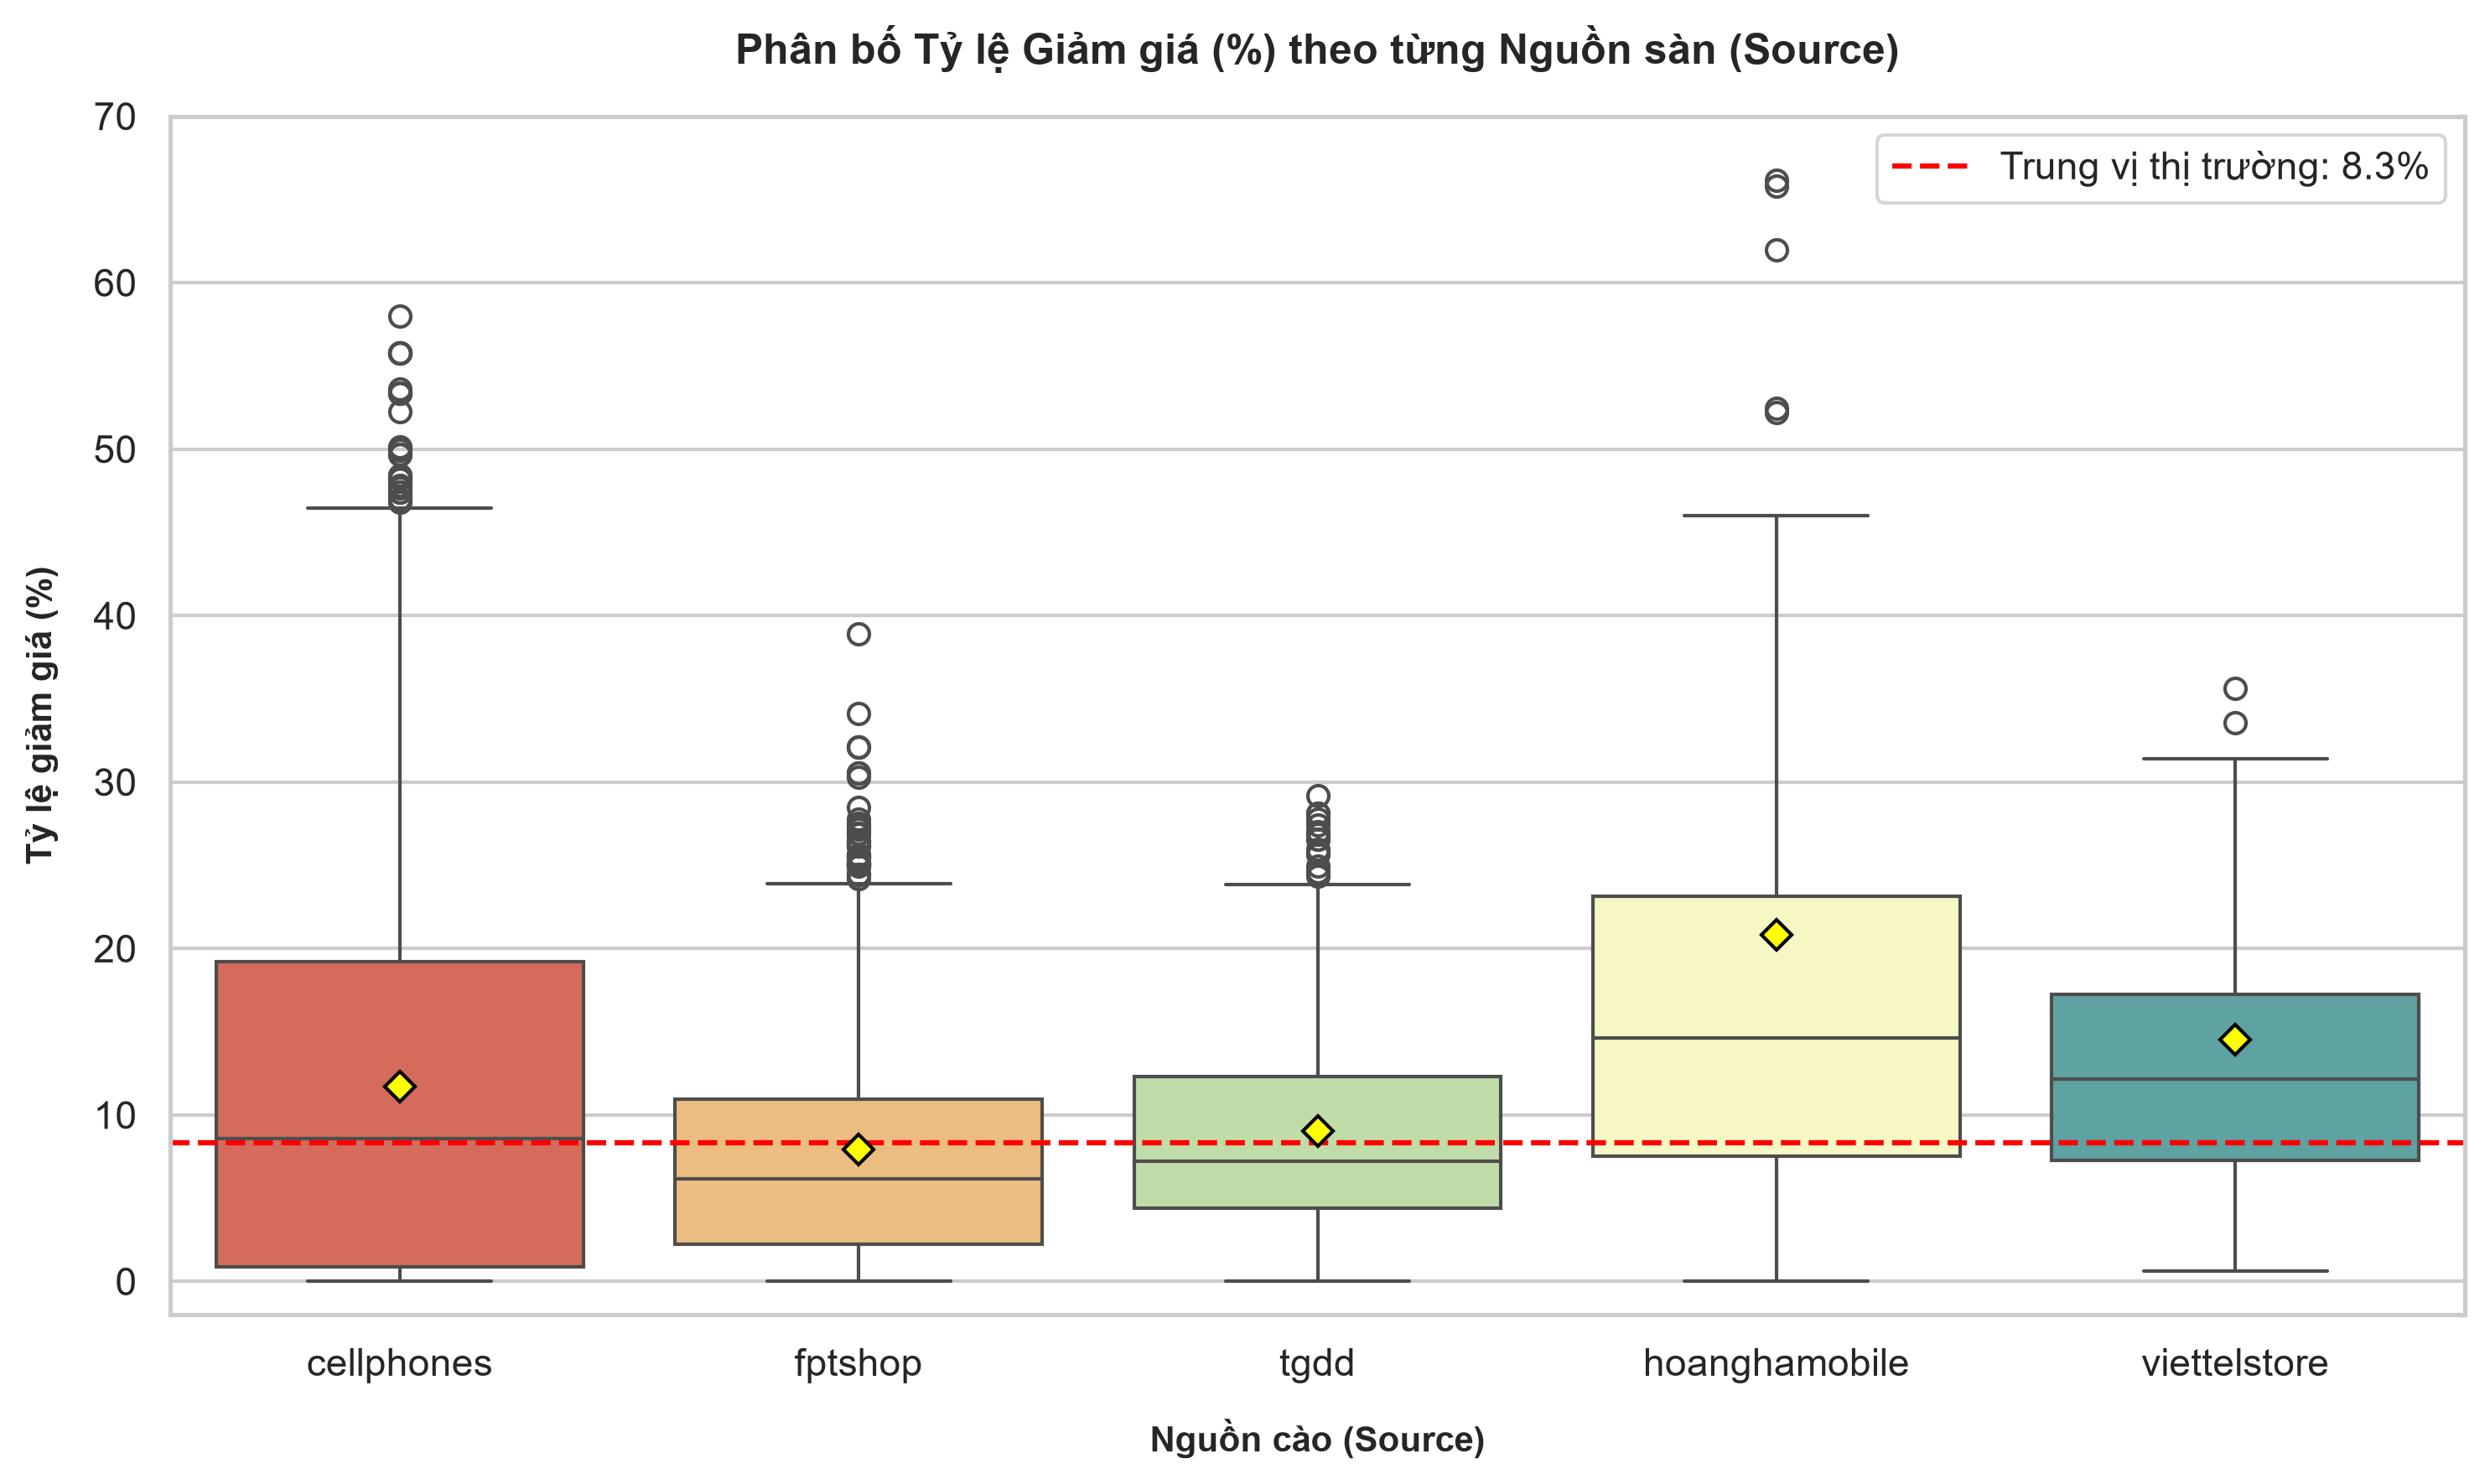

In [5]:
discount_df = compute_discount_stats_by_source(df)
display(discount_df)

fig2_path = "src/eda/outputs/figures/fig_1_2_discount_rate_by_source.png"
plot_discount_rate_by_source(df, fig2_path)
from IPython.display import Image, display
display(Image(fig2_path))


## 4. Kết luận cốt lõi cho Báo cáo & Bàn giao TV5

1. **Phân phối giá gốc cực kỳ lệch phải (Heavy-tailed Right-skewed)**:
   * Toàn thị trường: Skewness = 3,47; Kurtosis = 34,48.
   * Smartphone có độ lệch cực đoan (Skewness = 7,38; Kurtosis = 170,71) do sự xuất hiện của các phiên bản siêu cao cấp (đạt đỉnh 485 triệu VNĐ).
   * Giá trị trung vị (Median) thấp hơn đáng kể so với Giá trị trung bình (Mean): Laptop có Median 26,84 triệu (Mean 32,99 triệu); Smartphone có Median 7,99 triệu (Mean 13,99 triệu).

2. **Hiệu quả vượt trội của phép biến đổi Log**:
   * Sau khi chuyển sang thang `log10(price_vnd)` hoặc `log1p(price_vnd)`:
     * Độ lệch của **Laptop** giảm từ 2,89 xuống **0,29** (xấp xỉ phân phối chuẩn hoàn hảo Gaussian).
     * Độ lệch của **Smartphone** giảm từ 7,38 xuống **-0,58**.
   * **Khuyến nghị bắt buộc cho TV5**: Bắt buộc sử dụng hàm mục tiêu log khi huấn luyện các mô hình hồi quy (OLS, Ridge, Lasso, Neural Network) để tránh sai số dự báo bị chi phối bởi các mẫu giá cực cao.

3. **Chính sách giảm giá giữa các sàn**:
   * Tỷ lệ chiết khấu trung vị của thị trường là **8,34%** (Mean: 11,50%).
   * FPT Shop có tỷ lệ hiển thị giảm giá cao nhất (99,88% sản phẩm có giảm giá) nhưng mức giảm vừa phải (trung vị 6,16%).
   * Hoàng Hà Mobile có mức chiết khấu trung vị cao nhất thị trường (**14,61%**), định vị là kênh bán lẻ cạnh tranh mạnh về giá.